**Name: K.Raaga Priya**

**Registration Number:AP24110011208**

**Section:M**

   Principal Component  Explained Variance (%)  Cumulative Variance (%)
0                  PC1                   28.69                    28.69
1                  PC2                   17.08                    45.77
2                  PC3                   14.31                    60.07
3                  PC4                   11.01                    71.09
4                  PC5                    8.71                    79.80
5                  PC6                    6.05                    85.85
6                  PC7                    5.07                    90.92
7                  PC8                    3.81                    94.73
8                  PC9                    3.13                    97.86
9                 PC10                    1.61                    99.47
10                PC11                    0.53                   100.00


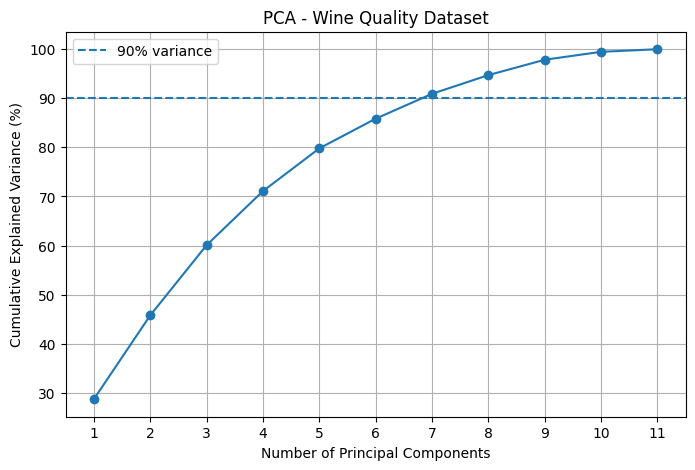


First five transformed records:
        PC1       PC2
0 -1.561545  0.444892
1 -0.760892  1.915058
2 -0.708085  0.914423
3  2.308166 -0.224448
4 -1.561545  0.444892

Variance retained by 2 components: 45.77 %


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
df = pd.read_csv("/content/WineQT.csv")

# Select features and exclude target and ID
X = df.drop(columns=["quality", "Id"])

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_ * 100
cumulative_variance = explained_variance.cumsum()                                   #AP24110011208

# Display results
results = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance (%)": explained_variance,
    "Cumulative Variance (%)": cumulative_variance
})

print(results.round(2))

# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=90, linestyle="--", label="90% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Wine Quality Dataset")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)
plt.legend()
plt.show()

# Reduce the dataset to 2 principal components
pca_2 = PCA(n_components=2)
X_2d = pca_2.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_2d, columns=["PC1", "PC2"])
print("\nFirst five transformed records:")
print(pca_df.head())
#AP24110010230
print("\nVariance retained by 2 components:",
      round(pca_2.explained_variance_ratio_.sum() * 100, 2), "%")


Question 1: What happens if we change the number of components?
Change PCA(n_components=2) to PCA(n_components=3).


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("/content/WineQT.csv")

X = df.drop(columns=["Id", "quality"])

# Standardize the data
X_scaled = StandardScaler().fit_transform(X)

# PCA with 2 components
pca2 = PCA(n_components=2)
X2 = pca2.fit_transform(X_scaled)                                                  #AP24110011208

# PCA with 3 components
pca3 = PCA(n_components=3)
X3 = pca3.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Shape with 2 components:", X2.shape)
print("Shape with 3 components:", X3.shape)

print("Variance with 2 components:",
      pca2.explained_variance_ratio_.sum() * 100, "%")

print("Variance with 3 components:",
      pca3.explained_variance_ratio_.sum() * 100, "%")

Original shape: (1143, 11)
Shape with 2 components: (1143, 2)
Shape with 3 components: (1143, 3)
Variance with 2 components: 45.76744847276905 %
Variance with 3 components: 60.073376561859604 %


Question 2: What happens if standardization is removed?
Replace X_scaled with X in the PCA transformation.


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("/content/WineQT.csv")
X = df.drop(columns=["Id", "quality"])

# PCA with standardization
X_scaled = StandardScaler().fit_transform(X)

pca_scaled = PCA()
pca_scaled.fit(X_scaled)

print("Variance ratio with standardization:")
print(pca_scaled.explained_variance_ratio_)                                        #AP24110011208

# PCA without standardization
pca_original = PCA()
pca_original.fit(X)

print("\nVariance ratio without standardization:")
print(pca_original.explained_variance_ratio_)

Variance ratio with standardization:
[0.28692345 0.17075104 0.14305928 0.1101368  0.08711032 0.06048811
 0.05069067 0.03809625 0.03131763 0.01611195 0.0053145 ]

Variance ratio without standardization:
[9.47181493e-01 4.77784046e-02 2.67155131e-03 1.39939477e-03
 8.94305451e-04 3.58441216e-05 1.91896822e-05 1.01127645e-05
 8.51823916e-06 1.18567288e-06 4.73800743e-10]


Question 3: What happens if we retain more components?
Try 1, 2, 3, 5 and 10 principal components.


1 components: 28.69% variance retained
2 components: 45.77% variance retained
3 components: 60.07% variance retained
5 components: 79.80% variance retained
10 components: 99.47% variance retained

Components required for 90% variance: 7


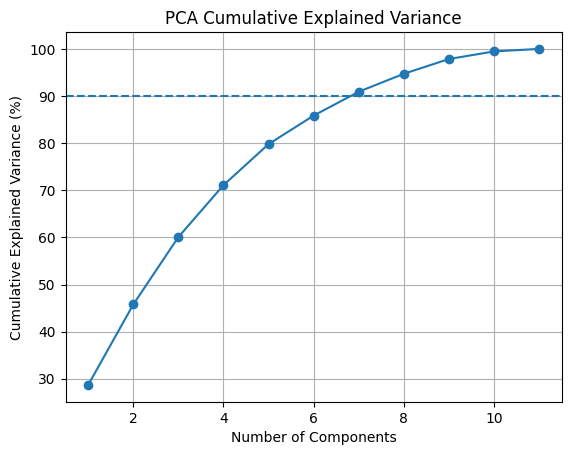

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("/content/WineQT.csv")
X = df.drop(columns=["Id", "quality"])

X_scaled = StandardScaler().fit_transform(X)

# Fit PCA on all components
pca = PCA()
pca.fit(X_scaled)                                                                    #AP24110011208

cumulative = pca.explained_variance_ratio_.cumsum() * 100

# Test different component counts
for n in [1, 2, 3, 5, 10]:
    print(f"{n} components: {cumulative[n-1]:.2f}% variance retained")

# Find components needed for 90% variance
pca90 = PCA(n_components=0.90)
pca90.fit(X_scaled)

print("\nComponents required for 90% variance:",
      pca90.n_components_)

# Plot cumulative variance
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(y=90, linestyle="--")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Cumulative Explained Variance")
plt.grid(True)
plt.show()

Question 4: What happens to the visualization?
Plot the first two principal components and observe the three wine classes.


Reduced shape: (1143, 2)
Variance retained: 45.76744847276905 %


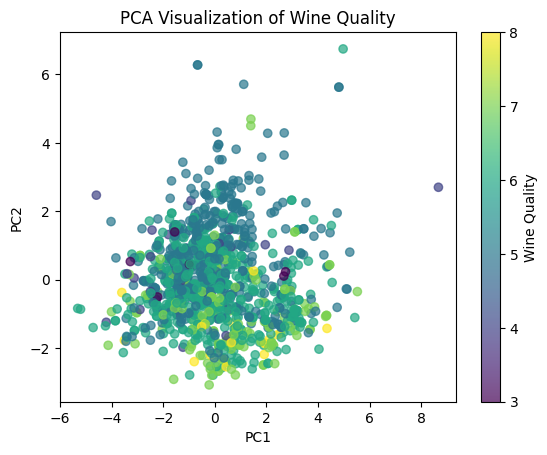

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("/content/WineQT.csv")

X = df.drop(columns=["Id", "quality"])
y = df["quality"]

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# Reduce to two components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Reduced shape:", X_pca.shape)
print("Variance retained:",
      pca.explained_variance_ratio_.sum() * 100, "%")                                            #AP24110011208

# Plot wine quality classes
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Visualization of Wine Quality")
plt.colorbar(label="Wine Quality")
plt.show()

Question 5: Does PCA select existing features?

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("/content/WineQT.csv")
X = df.drop(columns=["Id", "quality"])

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# Extract two principal components
pca = PCA(n_components=2)
X_extracted = pca.fit_transform(X_scaled)

# Display original and extracted features
print("Original features:")
print(list(X.columns))

print("\nExtracted features:")
print(["PC1", "PC2"])

print("\nFirst five extracted records:")
pca_df = pd.DataFrame(X_extracted, columns=["PC1", "PC2"])                                     #AP24110011208
print(pca_df.head())

print("\nPrincipal component weights:")
weights = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2"]
)
print(weights.round(3))

Original features:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Extracted features:
['PC1', 'PC2']

First five extracted records:
        PC1       PC2
0 -1.561545  0.444892
1 -0.760892  1.915058
2 -0.708085  0.914423
3  2.308166 -0.224448
4 -1.561545  0.444892

Principal component weights:
     fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
PC1          0.485            -0.227        0.460           0.175      0.225   
PC2         -0.102             0.289       -0.147           0.252      0.153   

     free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
PC1               -0.048                 0.015    0.400 -0.433      0.238   
PC2                0.517                 0.577    0.218 -0.006     -0.062   

     alcohol  
PC1   -0.119  
PC2   -0.382  
